# Гибридная рекомендательная система книг

**Сессионный проект по дисциплине «Рекомендательные системы»**  
**Выполнила:** Вдовина Д. Н.

**Цель:** разработать и оценить гибридную рекомендательную систему на основе датасета Goodbooks-10k, объединяющую несколько алгоритмов рекомендаций.

In [1]:
# импортируем необходимые библиотеки
from pathlib import Path
from itertools import product
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.sparse import load_npz
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score

# Общие настройки
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

# Итоговые параметры модели
ITEMCF_K = 5

HYBRID_WEIGHTS = {
    "Content": 0.1,
    "ItemCF": 0.7,
    "Popularity": 0.2,
    "SVD": 0.0
}

MODEL_NAMES = list(HYBRID_WEIGHTS)

In [2]:
# Загрузка данных Goodbooks-10k
DATA_DIRECTORY = Path("../data")

ratings = pd.read_csv(DATA_DIRECTORY / "ratings.csv")
books = pd.read_csv(DATA_DIRECTORY / "books.csv")
tags = pd.read_csv(DATA_DIRECTORY / "tags.csv")
book_tags = pd.read_csv(DATA_DIRECTORY / "book_tags.csv")

print("Оценки:", ratings.shape)
print("Книги:", books.shape)
print("Теги:", tags.shape)
print("Связи книг с тегами:", book_tags.shape)

Оценки: (5976479, 3)
Книги: (10000, 23)
Теги: (34252, 2)
Связи книг с тегами: (999912, 3)


In [3]:
# Загружаем готовые выборки из домашнего задания
processed_dir = Path("../processed")

train = pd.read_parquet(processed_dir / "train.parquet")
validation = pd.read_parquet(processed_dir / "validation.parquet")
test = pd.read_parquet(processed_dir / "test.parquet")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Train: (3564488, 3)
Validation: (1195271, 3)
Test: (1216720, 3)


In [4]:
# Загружаем подготовленные профили книг
book_profiles = pd.read_parquet(
    processed_dir / "book_profiles.parquet"
)

print("Профили книг:", book_profiles.shape)
display(book_profiles.head(3))

Профили книг: (10000, 5)


,book_id,original_title,title,tags_text,text_profile
0,1,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",young_adult science_fiction fiction dystopian ...,The Hunger Games young_adult science_fiction f...
1,2,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,fantasy young_adult fiction harry_potter serie...,Harry Potter and the Philosopher's Stone fanta...
2,3,Twilight,"Twilight (Twilight, #1)",young_adult fantasy vampires fiction paranorma...,Twilight young_adult fantasy vampires fiction ...


In [5]:
# Загружаем TF-IDF-матрицу из домашнего задания

models_dir = Path("../models")
tfidf_matrix = load_npz(models_dir / "tfidf_matrix.npz")

print("Размерность TF-IDF-матрицы:", tfidf_matrix.shape)
print("Количество ненулевых элементов:", tfidf_matrix.nnz)

Размерность TF-IDF-матрицы: (10000, 10000)
Количество ненулевых элементов: 313423


In [6]:
# Загружаем матрицу Item–User из домашнего задания
item_user_matrix = load_npz(models_dir / "item_user_matrix.npz")

print("Размерность Item–User:", item_user_matrix.shape)
print("Количество ненулевых элементов:", item_user_matrix.nnz)

Размерность Item–User: (10000, 53424)
Количество ненулевых элементов: 3564488


In [7]:
# Загружаем обученную модель SVD

with open(models_dir / "svd_model.pkl", "rb") as file:
    svd_model = pickle.load(file)

print("Модель SVD успешно загружена")
print("Прогноз для пользователя 1 и книги 5:",
      round(svd_model.predict(1, 5).est, 4))

Модель SVD успешно загружена
Прогноз для пользователя 1 и книги 5: 3.7358


In [8]:
# Загружаем соответствия идентификаторов и индексов
with open(models_dir / "id_mappings.pkl", "rb") as file:
    id_mappings = pickle.load(file)

book_id_to_idx = id_mappings["book_id_to_idx"]
user_id_to_idx = id_mappings["user_id_to_idx"]

print("Книг в словаре:", len(book_id_to_idx))
print("Пользователей в словаре:", len(user_id_to_idx))

Книг в словаре: 10000
Пользователей в словаре: 53424


In [9]:
# Проверяем соответствие ID книг и строк матриц
book_ids = book_profiles["book_id"].tolist()

mapping_correct = all(
    book_id_to_idx[book_id] == i
    for i, book_id in enumerate(book_ids)
)

print("Соответствие индексов книг:", mapping_correct)
print("Количество книг:", len(book_ids))
print("Строк TF-IDF:", tfidf_matrix.shape[0])
print("Строк Item-User:", item_user_matrix.shape[0])

assert mapping_correct, "Ошибка соответствия индексов книг"
assert tfidf_matrix.shape[0] == len(book_ids)
assert item_user_matrix.shape[0] == len(book_ids)

Соответствие индексов книг: True
Количество книг: 10000
Строк TF-IDF: 10000
Строк Item-User: 10000


In [10]:
# Проверяем соответствие Item–User-матрицы обучающей выборке
train_rows = train["book_id"].map(book_id_to_idx).to_numpy()
train_cols = train["user_id"].map(user_id_to_idx).to_numpy()
train_values = train["rating"].to_numpy()

matrix_values = np.asarray(
    item_user_matrix[train_rows, train_cols]
).ravel()

print("Оценок в Train:", len(train))
print("Ненулевых элементов матрицы:", item_user_matrix.nnz)
print("Все оценки совпадают:", np.array_equal(matrix_values, train_values))

assert item_user_matrix.nnz == len(train)
assert np.array_equal(matrix_values, train_values)

print("Item–User-матрица соответствует Train")


Оценок в Train: 3564488
Ненулевых элементов матрицы: 3564488
Все оценки совпадают: True
Item–User-матрица соответствует Train


In [11]:
# Проверяем обучающую выборку сохранённой SVD
svd_trainset = svd_model.trainset

print("Оценок в текущем Train:", len(train))
print("Оценок при обучении SVD:", svd_trainset.n_ratings)

print("Пользователей в SVD:", svd_trainset.n_users)
print("Книг в SVD:", svd_trainset.n_items)

assert svd_trainset.n_ratings == len(train), (
    "Размер обучающей выборки SVD не совпадает с текущим Train"
)

Оценок в текущем Train: 3564488
Оценок при обучении SVD: 3564488
Пользователей в SVD: 53424
Книг в SVD: 10000


In [12]:
# Проверяем фактические взаимодействия, использованные при обучении SVD
sample = train.sample(n=1000, random_state=RANDOM_STATE)

matches = 0

for row in sample.itertuples(index=False):
    user_id = svd_trainset.to_inner_uid(row.user_id)
    book_id = svd_trainset.to_inner_iid(row.book_id)

    user_ratings = dict(svd_trainset.ur[user_id])

    if user_ratings.get(book_id) == row.rating:
        matches += 1

print("Проверено взаимодействий:", len(sample))
print("Совпадающих оценок:", matches)

assert matches == len(sample), "Обнаружены расхождения в SVD"

print("Проверенные взаимодействия SVD соответствуют Train")

Проверено взаимодействий: 1000
Совпадающих оценок: 1000
Проверенные взаимодействия SVD соответствуют Train


In [13]:
# Полностью сравниваем обучающие данные SVD и Item–User
from scipy.sparse import coo_matrix

svd_book_indices = np.array([
    book_id_to_idx[svd_trainset.to_raw_iid(i)]
    for i in range(svd_trainset.n_items)
])

svd_user_indices = np.array([
    user_id_to_idx[svd_trainset.to_raw_uid(i)]
    for i in range(svd_trainset.n_users)
])

svd_ratings = np.fromiter(
    svd_trainset.all_ratings(),
    dtype=[("user", "i4"), ("book", "i4"), ("rating", "f8")],
    count=svd_trainset.n_ratings
)

svd_matrix = coo_matrix(
    (
        svd_ratings["rating"],
        (
            svd_book_indices[svd_ratings["book"]],
            svd_user_indices[svd_ratings["user"]]
        )
    ),
    shape=item_user_matrix.shape
).tocsr()

differences = svd_matrix - item_user_matrix
differences.eliminate_zeros()

print("Несовпадающих элементов:", differences.nnz)

assert differences.nnz == 0
print("Все обучающие взаимодействия SVD соответствуют Train")

Несовпадающих элементов: 0
Все обучающие взаимодействия SVD соответствуют Train


In [14]:
# Проверяем корректность TF-IDF-матрицы
row_norms = np.sqrt(
    tfidf_matrix.multiply(tfidf_matrix).sum(axis=1)
).A1

nonempty = row_norms > 0

print("Количество книг:", tfidf_matrix.shape[0])
print("Количество текстовых признаков:", tfidf_matrix.shape[1])
print("Книг с ненулевыми векторами:", nonempty.sum())
print("Некорректных значений:", (~np.isfinite(tfidf_matrix.data)).sum())
print(
    "Все непустые векторы L2-нормализованы:",
    np.allclose(row_norms[nonempty], 1.0, atol=1e-5)
)

assert tfidf_matrix.shape[0] == len(book_profiles)
assert np.isfinite(tfidf_matrix.data).all()
assert np.allclose(row_norms[nonempty], 1.0, atol=1e-5)

Количество книг: 10000
Количество текстовых признаков: 10000
Книг с ненулевыми векторами: 10000
Некорректных значений: 0
Все непустые векторы L2-нормализованы: True


In [15]:
# Проверяем повторяющиеся пары пользователь–книга
all_ratings = pd.concat([train, validation, test])

duplicates = all_ratings.duplicated(
    subset=["user_id", "book_id"]
).sum()

print("Повторяющихся пар пользователь–книга:", duplicates)

Повторяющихся пар пользователь–книга: 0


### Вывод по подготовке данных

Использованы выборки Train (60%), Validation (20%) и Test (20%), подготовленные в предыдущем домашнем задании.

Повторяющихся пар пользователь–книга не обнаружено. Это подтверждает отсутствие пересечений по таким парам между выборками. Для предотвращения утечки информации поведенческие признаки далее рассчитываются только на Train.

## Расширенные признаки

На основе Train сформируем признаки пользователей и книг: активность, средние оценки, популярность, разброс оценок и тематические характеристики.

Для оценки соответствия книг интересам пользователей используем TF-IDF-представления.

In [16]:
# Создаём признаки пользователей по обучающей выборке
user_features = train.groupby("user_id")["rating"].agg(
    user_avg_rating="mean",
    user_rating_count="count"
).reset_index()

print("Признаки пользователей:", user_features.shape)
display(user_features.head())

Признаки пользователей: (53424, 3)


,user_id,user_avg_rating,user_rating_count
0,1,3.6857,70
1,2,4.4103,39
2,3,1.6852,54
3,4,3.8250,80
4,5,4.0667,60


In [17]:
# Создаём признаки книг по обучающей выборке
book_features = train.groupby("book_id")["rating"].agg(
    book_avg_rating="mean",
    book_rating_count="count",
    book_rating_std="std"
).reset_index()

# Для книг с одной оценкой заменяем неопределённое стандартное отклонение на 0
book_features["book_rating_std"] = book_features["book_rating_std"].fillna(0)

print("Признаки книг:", book_features.shape)
display(book_features.head())

Признаки книг: (10000, 4)


,book_id,book_avg_rating,book_rating_count,book_rating_std
0,1,4.2756,13543,0.8673
1,2,4.3524,13029,0.8667
2,3,3.2137,10214,1.3771
3,4,4.3344,11348,0.8571
4,5,3.7725,9855,1.0466


In [18]:
# Разделяем пользователей на три группы по активности
user_features["activity_group"] = pd.qcut(
    user_features["user_rating_count"],
    q=3,
    labels=["Низкая", "Средняя", "Высокая"]
)

print("Распределение пользователей по активности:")
display(user_features["activity_group"].value_counts())

Распределение пользователей по активности:


activity_group
Низкая     18112
Средняя    17700
Высокая    17612
Name: count, dtype: int64

In [19]:
# Проверяем диапазоны активности пользователей
activity_stats = user_features.groupby(
    "activity_group", observed=True
)["user_rating_count"].agg(
    min_ratings="min",
    max_ratings="max",
    avg_ratings="mean"
)

display(activity_stats.round(1))

,min_ratings,max_ratings,avg_ratings
activity_group,,,
Низкая,11,60,50.6000
Средняя,61,72,66.3000
Высокая,73,120,83.7000


In [20]:
# Создаём шесть бинарных тематических признаков по тегам книг
genres = [
    "fantasy",
    "romance",
    "mystery",
    "science_fiction",
    "history",
    "horror"
]

book_genres = book_profiles[["book_id", "tags_text"]].copy()

for genre in genres:
    book_genres[genre] = book_genres["tags_text"].fillna("").apply(
        lambda tags: int(genre in tags.split())
    )

# Добавляем жанровые признаки к характеристикам книг
book_features = book_features.merge(
    book_genres.drop(columns="tags_text"),
    on="book_id",
    how="left"
)

print("Признаки книг:", book_features.shape)
display(book_features.head())

Признаки книг: (10000, 10)


,book_id,book_avg_rating,book_rating_count,book_rating_std,fantasy,romance,mystery,science_fiction,history,horror
0,1,4.2756,13543,0.8673,1,1,0,1,0,0
1,2,4.3524,13029,0.8667,1,0,0,0,0,0
2,3,3.2137,10214,1.3771,1,0,0,1,0,1
3,4,4.3344,11348,0.8571,0,0,0,0,0,0
4,5,3.7725,9855,1.0466,0,1,0,0,0,0


In [21]:
# Формируем профиль интересов пользователя

def get_user_profile(user_id):
    liked_books = train[
        (train["user_id"] == user_id) &
        (train["rating"] >= 4)
    ]

    if liked_books.empty:
        return None

    book_indices = liked_books["book_id"].map(book_id_to_idx).to_numpy()

    user_profile = tfidf_matrix[book_indices].mean(axis=0)
    user_profile = normalize(np.asarray(user_profile))

    return user_profile


# Проверяем профиль первого пользователя
user_profile = get_user_profile(1)

print("Размерность профиля:", user_profile.shape)

Размерность профиля: (1, 10000)


In [22]:
# Рассчитываем сходство пользователя с книгой

def get_user_book_similarity(user_id, book_id):
    user_profile = get_user_profile(user_id)

    if user_profile is None:
        return 0.0

    book_idx = book_id_to_idx[book_id]
    book_vector = tfidf_matrix[book_idx]

    similarity = cosine_similarity(user_profile, book_vector)[0, 0]

    return float(similarity)


# Проверяем на примере
similarity = get_user_book_similarity(user_id=1, book_id=5)

print("Сходство пользователя с книгой:", round(similarity, 4))

Сходство пользователя с книгой: 0.5156


### Итог подготовки признаков

Пользовательские и книжные признаки, тематические индикаторы и TF-IDF-профили вычисляются из Train / заранее подготовленных текстовых профилей. Данные Validation и Test не используются при расчёте статистик оценок.

## Генерация кандидатов

Четыре модели формируют до 50 рекомендаций каждая. Оценки нормализуются отдельно по моделям; отсутствие книги в Top-50 трактуется как нулевой вклад соответствующей модели, а не как доказательство нерелевантности.

In [23]:
# Рассчитываем взвешенный рейтинг популярности книг
C = train["rating"].mean()
m = book_features["book_rating_count"].median()

book_features["weighted_rating"] = (
    book_features["book_rating_count"] * book_features["book_avg_rating"] + m * C
) / (book_features["book_rating_count"] + m)

popular_books = book_features.sort_values(
    "weighted_rating", ascending=False
)

display(
    popular_books[
        ["book_id", "book_avg_rating", "book_rating_count", "weighted_rating"]
    ].head(10)
)

,book_id,book_avg_rating,book_rating_count,weighted_rating
861,862,4.7206,791,4.5945
421,422,4.6833,1121,4.5943
779,780,4.6742,841,4.5614
1307,1308,4.7096,544,4.5408
3627,3628,4.8404,282,4.5237
24,25,4.5242,9220,4.5146
1009,1010,4.6297,748,4.5125
1787,1788,4.7383,386,4.5116
561,562,4.5698,1074,4.4912
191,192,4.4987,2304,4.4638


In [24]:
# Формируем рекомендации на основе взвешенной популярности
def get_popularity_recommendations(user_id, N=10):
    rated_books = set(
        train.loc[train["user_id"] == user_id, "book_id"]
    )

    recommendations = popular_books[
        ~popular_books["book_id"].isin(rated_books)
    ]

    return recommendations.head(N)[
        ["book_id", "weighted_rating"]
    ].reset_index(drop=True)


# Проверяем рекомендации для первого пользователя
display(get_popularity_recommendations(user_id=1, N=5))

,book_id,weighted_rating
0,862,4.5945
1,422,4.5943
2,780,4.5614
3,1308,4.5408
4,3628,4.5237


In [25]:
# Формируем Content-Based рекомендации
def get_content_recommendations(user_id, N=10):
    user_profile = get_user_profile(user_id)

    if user_profile is None:
        return None

    # Сходство пользователя со всеми книгами
    scores = cosine_similarity(user_profile, tfidf_matrix).flatten()

    # Исключаем уже оценённые книги
    rated_books = train.loc[
        train["user_id"] == user_id, "book_id"
    ]

    for book_id in rated_books:
        scores[book_id_to_idx[book_id]] = -1

    # Выбираем наиболее подходящие книги
    top_indices = np.argsort(scores)[::-1][:N]

    recommendations = book_profiles.iloc[top_indices][["book_id", "title"]].copy()
    recommendations["similarity"] = scores[top_indices]

    return recommendations.reset_index(drop=True)


# Проверяем рекомендации
display(get_content_recommendations(user_id=1, N=5))

,book_id,title,similarity
0,4607,"Lila (Gilead, #3)",0.5322
1,172,Anna Karenina,0.5318
2,494,The Secret History,0.5214
3,5,The Great Gatsby,0.5156
4,63,Wuthering Heights,0.5123


In [26]:
# Формируем Item-Based CF рекомендации
def get_item_cf_recommendations(user_id, N=10, K=ITEMCF_K):
    user_ratings = train[train["user_id"] == user_id]

    liked_books = user_ratings[user_ratings["rating"] >= 4]

    if liked_books.empty:
        return None

    liked_indices = liked_books["book_id"].map(book_id_to_idx).to_numpy()
    weights = liked_books["rating"].to_numpy() - 3

    # Сходство понравившихся книг со всем каталогом
    similarities = cosine_similarity(
        item_user_matrix[liked_indices],
        item_user_matrix
    )

    weighted_similarities = similarities * weights[:, None]

    # Берём K наибольших значений для каждой книги
    top_k_values = np.sort(weighted_similarities, axis=0)[-K:]
    scores = top_k_values.sum(axis=0) / K

    # Исключаем уже оценённые книги
    rated_indices = user_ratings["book_id"].map(book_id_to_idx).to_numpy()
    scores[rated_indices] = -1

    top_indices = np.argsort(scores)[::-1]
    top_indices = top_indices[scores[top_indices] > 0][:N]

    recommendations = book_profiles.iloc[top_indices][
        ["book_id", "title"]
    ].copy()

    recommendations["score"] = scores[top_indices]

    return recommendations.reset_index(drop=True)


# Проверяем рекомендации
display(get_item_cf_recommendations(user_id=1, N=5))

,book_id,title,score
0,11,The Kite Runner,0.4053
1,31,The Help,0.4038
2,5,The Great Gatsby,0.3943
3,14,Animal Farm,0.3885
4,8,The Catcher in the Rye,0.3773


In [27]:
# Формируем рекомендации с помощью SVD
def get_svd_recommendations(user_id, N=10):
    rated_books = set(
        train.loc[train["user_id"] == user_id, "book_id"]
    )

    # Выбираем книги, которые пользователь ещё не оценивал
    candidate_books = books.loc[
        ~books["book_id"].isin(rated_books), "book_id"
    ]

    # Прогнозируем пользовательскую оценку каждой книги
    predictions = [
        (book_id, svd_model.predict(user_id, book_id).est)
        for book_id in candidate_books
    ]

    recommendations = pd.DataFrame(
        predictions,
        columns=["book_id", "predicted_rating"]
    )

    return recommendations.nlargest(
        N, "predicted_rating"
    ).reset_index(drop=True)


# Проверяем рекомендации
display(get_svd_recommendations(user_id=1, N=5))

,book_id,predicted_rating
0,8946,4.7612
1,3628,4.6570
2,6590,4.6117
3,862,4.5748
4,6361,4.5517


In [28]:
# Объединяем кандидатов от четырёх моделей
def generate_candidates(user_id, N=50):
    models = {
        "Popularity": (get_popularity_recommendations, "weighted_rating"),
        "Content": (get_content_recommendations, "similarity"),
        "ItemCF": (get_item_cf_recommendations, "score"),
        "SVD": (get_svd_recommendations, "predicted_rating")
    }

    candidates = []

    for model_name, (model_func, score_column) in models.items():
        recommendations = model_func(user_id, N=N)

        if recommendations is None or recommendations.empty:
            continue

        result = recommendations[["book_id", score_column]].copy()
        result.columns = ["book_id", "score"]
        result["model"] = model_name

        candidates.append(result)

    return pd.concat(candidates, ignore_index=True)


# Проверяем генерацию кандидатов
candidates = generate_candidates(user_id=1)

print("Всего рекомендаций:", len(candidates))
print("Уникальных книг:", candidates["book_id"].nunique())
display(candidates.groupby("model").size())

Всего рекомендаций: 200
Уникальных книг: 174


model
Content       50
ItemCF        50
Popularity    50
SVD           50
dtype: int64

In [29]:
# Единая подготовка нормализованных оценок кандидатов
def make_candidate_scores(user_id, N=50):
    candidates = generate_candidates(user_id, N=N).copy()
    if candidates.empty:
        return pd.DataFrame(columns=MODEL_NAMES, dtype=float).rename_axis("book_id")

    min_scores = candidates.groupby("model")["score"].transform("min")
    max_scores = candidates.groupby("model")["score"].transform("max")
    candidates["normalized_score"] = (
        (candidates["score"] - min_scores) /
        (max_scores - min_scores).replace(0, np.nan)
    ).fillna(1.0)

    return candidates.pivot_table(
        index="book_id", columns="model",
        values="normalized_score", fill_value=0
    ).reindex(columns=MODEL_NAMES, fill_value=0)

candidate_scores = make_candidate_scores(user_id=1)
print("Уникальных кандидатов для пользователя 1:", len(candidate_scores))
display(candidate_scores.head())

Уникальных кандидатов для пользователя 1: 174


model,Content,ItemCF,Popularity,SVD
book_id,,,,
1,0.0000,0.6381,0.0000,0.0000
2,0.0000,0.7173,0.0049,0.0000
3,0.0000,0.1709,0.0000,0.0000
5,0.8676,0.9195,0.0000,0.0000
7,0.0000,0.6180,0.0000,0.0000


## Гибридное ранжирование

Итоговая оценка книги рассчитывается как взвешенная сумма нормализованных оценок базовых моделей.
Используем выбранную на Validation конфигурацию: `K=5`, Content — 0,1, ItemCF — 0,7, Popularity — 0,2, SVD — 0.
SVD участвует в генерации кандидатов, но не влияет непосредственно на итоговый балл.

In [30]:
# Основная функция гибридного ранжирования
def get_hybrid_recommendations(user_id, N=10, weights=None):
    if weights is None:
        weights = HYBRID_WEIGHTS
    scores = make_candidate_scores(user_id)
    if scores.empty:
        return pd.DataFrame(columns=["book_id", "title", "hybrid_score"])

    scores["hybrid_score"] = sum(
        scores[model] * weight for model, weight in weights.items()
    )
    return (
        scores.nlargest(N, "hybrid_score")[["hybrid_score"]]
        .reset_index()
        .merge(books[["book_id", "title"]], on="book_id")
        [["book_id", "title", "hybrid_score"]]
        .reset_index(drop=True)
    )

display(get_hybrid_recommendations(user_id=1, N=10))

,book_id,title,hybrid_score
0,5,The Great Gatsby,0.7304
1,31,The Help,0.7151
2,11,The Kite Runner,0.7000
3,14,Animal Farm,0.6142
4,8,The Catcher in the Rye,0.5964
5,33,Memoirs of a Geisha,0.5583
6,28,Lord of the Flies,0.5092
7,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.5031
8,1,"The Hunger Games (The Hunger Games, #1)",0.4467
9,10,Pride and Prejudice,0.4431


In [31]:
# Метрики качества рекомендаций
def precision_at_k(recommended, relevant, k=10):
    recommended = list(dict.fromkeys(recommended))[:k]
    relevant = set(relevant)

    hits = sum(book_id in relevant for book_id in recommended)
    return hits / k


def recall_at_k(recommended, relevant, k=10):
    recommended = list(dict.fromkeys(recommended))[:k]
    relevant = set(relevant)

    if not relevant:
        return 0.0

    hits = sum(book_id in relevant for book_id in recommended)
    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k=10):
    recommended = list(dict.fromkeys(recommended))[:k]
    relevant = set(relevant)

    dcg = sum(
        1 / np.log2(i + 2)
        for i, book_id in enumerate(recommended)
        if book_id in relevant
    )

    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(i + 2)
        for i in range(ideal_hits)
    )

    return dcg / idcg if idcg > 0 else 0.0

## Оценка на Validation

На 100 случайных пользователях с положительными оценками из Validation проводим предварительное сравнение. 70 пользователей используются для диагностического подбора, 30 — для сравнения вариантов; из-за многократного анализа той же Validation это **не независимая финальная оценка**. Test не используется для настройки.

In [32]:
# Выбираем пользователей с положительными оценками в Validation
eligible_users = validation.loc[
    validation["rating"] >= 4, "user_id"
].unique()

rng = np.random.default_rng(RANDOM_STATE)

sample_users = rng.choice(
    eligible_users,
    size=100,
    replace=False
)

print("Пользователей для оценки:", len(sample_users))
print("Первые 5 ID:", sample_users[:5])

Пользователей для оценки: 100
Первые 5 ID: [50295 36924 13267  9561 51409]


In [33]:
# Пользователи и релевантные книги для оценки
rng = np.random.default_rng(RANDOM_STATE)
shuffled_users = rng.permutation(sample_users)
tuning_users = shuffled_users[:70]
check_users = shuffled_users[70:]
relevant_by_user = (
    validation.loc[validation["rating"] >= 4]
    .groupby("user_id")["book_id"].agg(set).to_dict()
)
print("Настройка:", len(tuning_users), "Проверка:", len(check_users))

Настройка: 70 Проверка: 30


In [34]:
# Сравнение ItemCF и вариантов Hybrid на 30 пользователях
def evaluate_recommendations(recommend, users, relevant_lookup):
    rows = []
    for user_id in users:
        recommended = recommend(user_id)
        relevant = relevant_lookup.get(user_id, set())
        rows.append({
            "Precision@10": precision_at_k(recommended, relevant),
            "Recall@10": recall_at_k(recommended, relevant),
            "nDCG@10": ndcg_at_k(recommended, relevant)
        })
    return pd.DataFrame(rows).mean()

def itemcf_ids(user_id):
    rec = get_item_cf_recommendations(user_id, N=10)
    return rec["book_id"].tolist() if rec is not None else []

models_validation = {
    "ItemCF (K=5)": lambda u: itemcf_ids(u),
    "Hybrid (равные веса)": lambda u: get_hybrid_recommendations(
        u, weights=dict.fromkeys(MODEL_NAMES, 0.25)
    )["book_id"].tolist(),
    "Hybrid (выбранные веса)": lambda u: get_hybrid_recommendations(u)["book_id"].tolist()
}
val_comparison = pd.DataFrame({
    name: evaluate_recommendations(fn, check_users, relevant_by_user)
    for name, fn in models_validation.items()
}).T
print("Проверка на 30 пользователях Validation:")
display(val_comparison.round(4))

Проверка на 30 пользователях Validation:


,Precision@10,Recall@10,nDCG@10
ItemCF (K=5),0.2367,0.1573,0.2724
Hybrid (равные веса),0.1233,0.0889,0.1433
Hybrid (выбранные веса),0.2433,0.1613,0.2756


### Промежуточный вывод
На 30 пользователях Validation гибрид с выбранными весами показал nDCG@10 = 0,2756 против 0,2724 у ItemCF. Использование равных весов существенно ухудшило качество (nDCG@10 = 0,1433).

Полученные результаты подтверждают важность выбора весов, однако преимущество Hybrid над ItemCF невелико и требует осторожной интерпретации из-за малого размера выборки.

### Проверка генерации кандидатов

Сравниваем полноту пула кандидатов с теоретическим максимумом Recall@10. Это диагностическая проверка на Validation, не оценка на Test.

In [35]:
# Насколько хорошо четыре модели собирают кандидатов
candidate_rows = []
for user_id in check_users:
    pool = set(generate_candidates(user_id, N=50)["book_id"])
    relevant = relevant_by_user.get(user_id, set())
    if not relevant:
        continue
    found = len(pool & relevant)
    candidate_rows.append({
        "Число кандидатов": len(pool),
        "Candidate Recall": found / len(relevant),
        "Максимальный Recall@10": min(10, found) / len(relevant)
    })

display(pd.DataFrame(candidate_rows).mean().round(4))

Число кандидатов         168.5333
Candidate Recall           0.4793
Максимальный Recall@10     0.4428
dtype: float64

In [36]:
# Вклад отдельных моделей в нахождение релевантных книг
contribution_rows = []
for user_id in check_users:
    candidates = generate_candidates(user_id, N=50)
    relevant = relevant_by_user.get(user_id, set())
    itemcf_books = set(candidates.loc[candidates["model"] == "ItemCF", "book_id"])
    for model in MODEL_NAMES:
        model_books = set(candidates.loc[candidates["model"] == model, "book_id"])
        contribution_rows.append({
            "Модель": model,
            "Релевантных": len(model_books & relevant),
            "Дополнительно к ItemCF": len((model_books - itemcf_books) & relevant)
        })

display(pd.DataFrame(contribution_rows).groupby("Модель").mean().round(3))

,Релевантных,Дополнительно к ItemCF
Модель,,
Content,3.5330,1.1330
ItemCF,6.3330,0.0000
Popularity,1.0330,0.1670
SVD,0.6000,0.2000


### Вывод по генерации кандидатов

Объединённый пул содержит в среднем 169 уникальных книг и охватывает 47,9% релевантных книг из Validation. Теоретически достижимый Recall@10 при идеальном ранжировании кандидатов составляет 0,4428.

Наибольшее количество релевантных книг находит ItemCF — в среднем 6,33 на пользователя. Content-Based дополнительно находит 1,13 релевантной книги, отсутствующей в кандидатах ItemCF. Вклад Popularity (0,17) и SVD (0,20) значительно меньше.

Таким образом, ItemCF является основным источником релевантных кандидатов, а Content-Based полезен для расширения их набора. При этом наличие книги в пуле не гарантирует её попадания в итоговый Top-10: качество системы зависит и от последующего ранжирования.

### Подбор количества соседей ItemCF

Влияние `K` оценивается на Validation. Для финального решения выбрано `K=5`; результат на Test используется только после фиксации параметров.

In [37]:
# Сравниваем K на группе настройки, не изменяя исходную функцию
k_rows = []
for k in [5, 10, 20]:
    for user_id in tuning_users:
        rec = get_item_cf_recommendations(user_id, N=10, K=k)
        ids = rec["book_id"].tolist() if rec is not None else []
        relevant = relevant_by_user.get(user_id, set())
        k_rows.append({
            "K": k,
            "Precision@10": precision_at_k(ids, relevant),
            "Recall@10": recall_at_k(ids, relevant),
            "nDCG@10": ndcg_at_k(ids, relevant)
        })

display(pd.DataFrame(k_rows).groupby("K").mean().round(4))

,Precision@10,Recall@10,nDCG@10
K,,,
5,0.1957,0.1249,0.2179
10,0.1857,0.1185,0.2066
20,0.1843,0.1165,0.2010


При сравнении K = 5, 10 и 20 на 70 пользователях Validation лучшие результаты по всем трём метрикам получены при K = 5 (nDCG@10 = 0,2179). Это значение выбрано для итоговой конфигурации ItemCF.

## Подбор весов Hybrid

Переберём комбинации весов четырёх моделей с шагом 0,1 при условии, что их сумма равна 1. Критерий выбора — максимальный средний nDCG@10 на 70 пользователях `tuning_users` из Validation.

Для ускорения расчётов нормализованные оценки кандидатов сохраняются заранее.

In [38]:
# Кэш кандидатов для воспроизводимого поиска весов
tuning_scores = {user_id: make_candidate_scores(user_id) for user_id in tuning_users}
weight_trials = []
for parts in product(range(11), repeat=4):
    if sum(parts) != 10:
        continue
    candidate_weights = np.array(parts) / 10
    ndcg_values = []
    for user_id, scores in tuning_scores.items():
        rank_scores = scores[MODEL_NAMES].to_numpy() @ candidate_weights
        ids = scores.index.to_numpy()[np.argsort(-rank_scores)[:10]]
        ndcg_values.append(ndcg_at_k(ids, relevant_by_user.get(user_id, set())))
    weight_trials.append(dict(zip(MODEL_NAMES, candidate_weights), **{
        "nDCG@10": np.mean(ndcg_values)
    }))
weight_search = pd.DataFrame(weight_trials).sort_values("nDCG@10", ascending=False)
print("Комбинаций:", len(weight_search))
display(weight_search.head(10).round(4))

Комбинаций: 286


,Content,ItemCF,Popularity,SVD,nDCG@10
117,0.1000,0.7000,0.2000,0.0000,0.2211
119,0.1000,0.8000,0.1000,0.0000,0.2211
116,0.1000,0.7000,0.1000,0.1000,0.2207
64,0.0000,0.9000,0.1000,0.0000,0.2206
61,0.0000,0.8000,0.1000,0.1000,0.2204
62,0.0000,0.8000,0.2000,0.0000,0.2203
118,0.1000,0.8000,0.0000,0.1000,0.2201
115,0.1000,0.7000,0.0000,0.2000,0.2200
120,0.1000,0.9000,0.0000,0.0000,0.2196
113,0.1000,0.6000,0.2000,0.1000,0.2195


In [39]:
# Сравниваем выбранные веса с исходным вариантом на check_users
weight_variants = {
    "Исходные": {"Content": 0.0, "ItemCF": 0.9, "Popularity": 0.1, "SVD": 0.0},
    "Выбранные": HYBRID_WEIGHTS
}
weight_check = pd.DataFrame({
    label: evaluate_recommendations(
        lambda u, w=configuration: get_hybrid_recommendations(u, weights=w)["book_id"].tolist(),
        check_users, relevant_by_user
    )
    for label, configuration in weight_variants.items()
}).T
display(weight_check.round(4))

,Precision@10,Recall@10,nDCG@10
Исходные,0.2367,0.1573,0.2759
Выбранные,0.2433,0.1613,0.2756


### Вывод по подбору весов

На 70 пользователях Validation выбрана конфигурация Content — 0,1, ItemCF — 0,7, Popularity — 0,2, SVD — 0, показавшая nDCG@10 = 0,2211.

На отдельной группе из 30 пользователей выбранные веса улучшили Precision@10 (0,2433 против 0,2367) и Recall@10 (0,1613 против 0,1573) относительно исходной конфигурации. При этом nDCG@10 практически не изменился и оказался немного ниже (0,2756 против 0,2759).

Таким образом, новая конфигурация показала небольшое улучшение полноты и точности, но её преимущество по качеству ранжирования не подтвердилось. Учитывая малый размер проверочной выборки и многократные эксперименты на Validation, различия следует интерпретировать осторожно. Параметры фиксируются до итоговой оценки на Test.

In [40]:
# Анализ качества по активности пользователей
rows = []
for user_id in check_users:
    rec = get_hybrid_recommendations(user_id)["book_id"].tolist()
    rows.append({"user_id": user_id, "nDCG@10": ndcg_at_k(
        rec, relevant_by_user.get(user_id, set())
    )})
segment_results = pd.DataFrame(rows).merge(
    user_features[["user_id", "activity_group"]], on="user_id"
)
display(segment_results.groupby("activity_group", observed=True).agg(
    users=("user_id", "count"), mean_ndcg=("nDCG@10", "mean")
).round(4))

,users,mean_ndcg
activity_group,,
Низкая,8,0.2732
Средняя,8,0.2304
Высокая,14,0.3027


In [41]:
# Расширенный анализ качества Hybrid по активности пользователей
segment_results = []

# Пользователи, участвовавшие в подборе и проверке параметров
excluded_users = set(sample_users)

# Пользователи с положительными оценками в Validation
eligible_users = set(relevant_by_user)

for group in ["Низкая", "Средняя", "Высокая"]:

    # Отбираем пользователей нужной группы
    
    group_users = user_features.loc[
    user_features["activity_group"] == group,
    "user_id"
]

    available_users = sorted(
        set(group_users) & eligible_users - excluded_users
    )

    # Выбираем до 100 пользователей
    selected_users = np.random.default_rng(RANDOM_STATE).choice(
        available_users,
        size=min(100, len(available_users)),
        replace=False
    )

    # Оцениваем готовую гибридную модель
    metrics = evaluate_recommendations(
        lambda u: get_hybrid_recommendations(u, N=10)["book_id"].tolist(),
        selected_users,
        relevant_by_user
    )

    segment_results.append({
        "Активность": group,
        "Пользователей": len(selected_users),
        **metrics
    })

segment_results = pd.DataFrame(segment_results).set_index("Активность")

display(segment_results.round(4))


,Пользователей,Precision@10,Recall@10,nDCG@10
Активность,,,,
Низкая,100,0.1770,0.1438,0.2016
Средняя,100,0.2020,0.1348,0.2226
Высокая,100,0.2230,0.1215,0.2501


### Вывод по расширенному анализу активности

На расширенной выборке из 300 пользователей Validation лучшие значения Precision@10 (0,2230) и nDCG@10 (0,2501) получены в группе высокой активности. При этом максимальный Recall@10 (0,1438) наблюдается у пользователей с низкой активностью.

Результаты по nDCG@10 согласуются с предварительным анализом на 30 пользователях: в обоих случаях наиболее высокое качество ранжирования наблюдается у высокоактивных пользователей.

Это позволяет предположить, что большее количество известных оценок помогает гибридной системе точнее упорядочивать рекомендации. Однако различия между группами не проверялись на статистическую значимость, поэтому делать вывод о причинном влиянии активности пока нельзя.

## Балансировка релевантности и разнообразия

Гибридная модель ранжирует книги по предполагаемой релевантности, но не учитывает их сходство между собой.

Для повышения разнообразия используем Maximum Marginal Relevance (MMR), который сочетает гибридный балл со штрафом за сходство с уже выбранными книгами.

Сходство определяем по TF-IDF-представлениям. Далее сравним релевантность и разнообразие рекомендаций до и после MMR.

In [42]:

# Переранжируем рекомендации с помощью MMR
def get_mmr_recommendations(user_id, N=10, lambda_param=0.6):
    candidates = get_hybrid_recommendations(user_id, N=50).copy()

    if candidates.empty:
        return candidates

    # Получаем TF-IDF-векторы книг
    indices = [book_id_to_idx[book_id] for book_id in candidates["book_id"]]
    vectors = tfidf_matrix[indices]

    # Рассчитываем косинусное сходство книг
    similarity = cosine_similarity(vectors)

    # Нормализуем гибридные оценки
    scores = candidates["hybrid_score"].to_numpy()
    relevance = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)

    selected = []
    remaining = list(range(len(candidates)))

    # Последовательно выбираем релевантные и непохожие книги
    while len(selected) < N and remaining:
        mmr_scores = []

        for i in remaining:
            max_similarity = similarity[i, selected].max() if selected else 0

            mmr_score = (
                lambda_param * relevance[i]
                - (1 - lambda_param) * max_similarity
            )
            mmr_scores.append(mmr_score)

        best = remaining[np.argmax(mmr_scores)]
        selected.append(best)
        remaining.remove(best)

    return candidates.iloc[selected].reset_index(drop=True)


# Проверяем рекомендации
print("Гибридные рекомендации:")
display(get_hybrid_recommendations(user_id=1, N=10))

print("Рекомендации после MMR:")
display(get_mmr_recommendations(user_id=1, N=10))


Гибридные рекомендации:


,book_id,title,hybrid_score
0,5,The Great Gatsby,0.7304
1,31,The Help,0.7151
2,11,The Kite Runner,0.7000
3,14,Animal Farm,0.6142
4,8,The Catcher in the Rye,0.5964
5,33,Memoirs of a Geisha,0.5583
6,28,Lord of the Flies,0.5092
7,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.5031
8,1,"The Hunger Games (The Hunger Games, #1)",0.4467
9,10,Pride and Prejudice,0.4431


Рекомендации после MMR:


,book_id,title,hybrid_score
0,5,The Great Gatsby,0.7304
1,31,The Help,0.7151
2,11,The Kite Runner,0.7000
3,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.5031
4,1,"The Hunger Games (The Hunger Games, #1)",0.4467
5,33,Memoirs of a Geisha,0.5583
6,14,Animal Farm,0.6142
7,7,The Hobbit,0.4326
8,10,Pride and Prejudice,0.4431
9,38,The Time Traveler's Wife,0.3982


In [43]:
# Измеряем среднее сходство книг в рекомендациях
def average_similarity(recommendations):
    if len(recommendations) < 2:
        return 0.0

    indices = [
        book_id_to_idx[book_id]
        for book_id in recommendations["book_id"]
    ]

    vectors = tfidf_matrix[indices]
    similarity = cosine_similarity(vectors)

    # Учитываем только пары разных книг
    upper = similarity[np.triu_indices(len(indices), k=1)]

    return float(upper.mean())


In [44]:
# Сравниваем разнообразие и качество до и после MMR
def evaluate_mmr(users, lambda_param=0.6):
    rows = []
    for user_id in users:
        relevant = relevant_by_user.get(user_id, set())
        for name, rec in {
            "Hybrid": get_hybrid_recommendations(user_id),
            "MMR": get_mmr_recommendations(user_id, lambda_param=lambda_param)
        }.items():
            ids = rec["book_id"].tolist()
            rows.append({
                "model": name,
                "Precision@10": precision_at_k(ids, relevant),
                "Recall@10": recall_at_k(ids, relevant),
                "nDCG@10": ndcg_at_k(ids, relevant),
                "Среднее сходство": average_similarity(rec)
            })
    return pd.DataFrame(rows).groupby("model").mean()

print("MMR на проверочных пользователях Validation:")
display(evaluate_mmr(check_users).round(4))

MMR на проверочных пользователях Validation:


,Precision@10,Recall@10,nDCG@10,Среднее сходство
model,,,,
Hybrid,0.2433,0.1613,0.2756,0.2275
MMR,0.2200,0.1445,0.2581,0.1472


### Вывод по MMR

На 30 пользователях Validation применение MMR при λ = 0,6 снизило среднее сходство рекомендованных книг с 0,2275 до 0,1472 (на 35,3%), что указывает на повышение тематического разнообразия.

При этом nDCG@10 уменьшился с 0,2756 до 0,2581, а Precision@10 и Recall@10 также снизились. Таким образом, MMR обеспечивает более разнообразные рекомендации ценой некоторого ухудшения релевантности.

Из-за небольшого размера выборки результаты рассматриваются как предварительные.

## Нейросетевой эксперимент: MLP

В качестве дополнительного эксперимента обучим MLP для ранжирования кандидатов гибридной системы.

Для обучения используем кандидатов с известными оценками из Validation, разделив пользователей на обучающую и проверочную группы без пересечений. Test не используется.

**Ограничение:** обучение только на размеченных взаимодействиях может создавать смещение выборки. Поэтому качество классификации MLP и качество итогового Top-10 будем оценивать отдельно.

In [45]:
# Выбираем пользователей для обучения нейросети
rng = np.random.default_rng(42)

# Исключаем пользователей предыдущих экспериментов
available_users = np.setdiff1d(
    validation["user_id"].unique(),
    sample_users
)

mlp_users = rng.choice(
    available_users, size=5000, replace=False
)

mlp_train_users = mlp_users[:4000]
mlp_val_users = mlp_users[4000:]

print("Пользователей для обучения MLP:", len(mlp_train_users))
print("Пользователей для проверки MLP:", len(mlp_val_users))
print("Пересечений с предыдущей выборкой:",
      len(np.intersect1d(mlp_users, sample_users)))


Пользователей для обучения MLP: 4000
Пользователей для проверки MLP: 1000
Пересечений с предыдущей выборкой: 0


In [46]:
# Создаём обучающие примеры с известной оценкой
mlp_train_parts = []
for user_id in mlp_train_users:
    scores = make_candidate_scores(user_id).reset_index()
    scores["user_id"] = user_id
    mlp_train_parts.append(scores)

mlp_train_data = pd.concat(mlp_train_parts, ignore_index=True).merge(
    validation[["user_id", "book_id", "rating"]],
    on=["user_id", "book_id"], how="inner"
)
mlp_train_data["target"] = (mlp_train_data["rating"] >= 4).astype(int)
print("Размеченных пар:", len(mlp_train_data))
print("Доля положительных:", round(mlp_train_data["target"].mean(), 4))

Размеченных пар: 31856
Доля положительных: 0.7931


Для обучения MLP получено 31 856 пар пользователь–книга с известными оценками из Validation. Доля положительных примеров составляет 79,31%.

Поскольку в обучающую выборку включаются только кандидаты с известной оценкой, она может отличаться от полного набора кандидатов, используемого при ранжировании. Это ограничение необходимо учитывать при интерпретации результатов MLP.

In [47]:
# Добавляем характеристики пользователей и книг
mlp_train_data = mlp_train_data.merge(
    user_features[["user_id", "user_avg_rating", "user_rating_count"]],
    on="user_id",
    how="left"
)

book_columns = [
    "book_id", "book_avg_rating", "book_rating_count",
    "book_rating_std", "weighted_rating",
    "fantasy", "romance", "mystery",
    "science_fiction", "history", "horror"
]

mlp_train_data = mlp_train_data.merge(
    book_features[book_columns],
    on="book_id",
    how="left"
)

print("Размер таблицы:", mlp_train_data.shape)
print("Пропущенных значений:", mlp_train_data.isna().sum().sum())

display(mlp_train_data.head())


Размер таблицы: (31856, 20)
Пропущенных значений: 0


,book_id,Content,ItemCF,Popularity,SVD,user_id,rating,target,user_avg_rating,user_rating_count,book_avg_rating,book_rating_count,book_rating_std,weighted_rating,fantasy,romance,mystery,science_fiction,history,horror
0,2,0.0000,0.6771,0.0120,0.0000,24144,4,1,4.0952,63,4.3524,13029,0.8667,4.3475,1,0,0,0,0,0
1,10,0.0000,0.0543,0.0000,0.0000,24144,5,1,4.0952,63,4.1923,7989,0.9793,4.1873,0,1,0,0,0,0
2,16,0.0000,0.3927,0.0000,0.0000,24144,4,1,4.0952,63,3.9967,8556,1.0323,3.9954,0,0,1,0,0,0
3,33,0.0000,0.6115,0.0000,0.0000,24144,5,1,4.0952,63,4.0024,6732,0.9226,4.0006,0,1,0,0,1,0
4,42,0.0000,0.1382,0.0000,0.0000,24144,4,1,4.0952,63,4.0039,6344,0.9804,4.0020,0,1,0,0,0,0


### Признаки MLP

Используются четыре нормализованные оценки базовых моделей, статистики пользователей и книг, шесть тематических индикаторов. Все числовые статистики оценок взяты из Train. Масштабирование `StandardScaler` обучается только на обучающих примерах MLP.

In [48]:
# Выбираем признаки для обучения нейросети
feature_columns = [
    "Content", "ItemCF", "Popularity", "SVD",
    "user_avg_rating", "user_rating_count",
    "book_avg_rating", "book_rating_count",
    "book_rating_std", "weighted_rating",
    "fantasy", "romance", "mystery",
    "science_fiction", "history", "horror"
]

X_train = mlp_train_data[feature_columns]
y_train = mlp_train_data["target"]

# Приводим признаки к сопоставимому масштабу
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

print("Размер X_train:", X_train_scaled.shape)
print("Размер y_train:", y_train.shape)
print("Количество признаков:", len(feature_columns))
print("Пропущенных значений:", np.isnan(X_train_scaled).sum())

Размер X_train: (31856, 16)
Размер y_train: (31856,)
Количество признаков: 16
Пропущенных значений: 0


In [49]:
# Обучаем небольшую нейросеть
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=0.01,
    max_iter=100,
    random_state=RANDOM_STATE
)

mlp_model.fit(X_train_scaled, y_train)

# Проверяем качество на обучающих данных
train_proba = mlp_model.predict_proba(X_train_scaled)[:, 1]

print("ROC-AUC на Train:", round(roc_auc_score(y_train, train_proba), 4))
print("Количество эпох:", mlp_model.n_iter_)

ROC-AUC на Train: 0.8048
Количество эпох: 100


/Users/darasaporeva/Projects/drug-ml-project/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [50]:
# Диагностика ROC-AUC на 200 отложенных пользователях
mlp_val_parts = []
for user_id in mlp_val_users[:200]:
    scores = make_candidate_scores(user_id).reset_index()
    scores["user_id"] = user_id
    mlp_val_parts.append(scores)

mlp_val_data = pd.concat(mlp_val_parts, ignore_index=True).merge(
    validation[["user_id", "book_id", "rating"]],
    on=["user_id", "book_id"], how="inner"
)
mlp_val_data["target"] = (mlp_val_data["rating"] >= 4).astype(int)
mlp_val_data = mlp_val_data.merge(
    user_features[["user_id", "user_avg_rating", "user_rating_count"]], on="user_id"
).merge(book_features[book_columns], on="book_id")
val_proba = mlp_model.predict_proba(
    scaler.transform(mlp_val_data[feature_columns])
)[:, 1]
print("Размеченных пар:", len(mlp_val_data))
print("ROC-AUC Validation:", round(roc_auc_score(mlp_val_data["target"], val_proba), 4))

Размеченных пар: 1599
ROC-AUC Validation: 0.7746


In [51]:
# Сравниваем Hybrid, MLP и их смесь на всех кандидатах
def get_mlp_ranking(user_id):
    scores = make_candidate_scores(user_id).reset_index()
    scores["user_id"] = user_id
    scores = scores.merge(
        user_features[["user_id", "user_avg_rating", "user_rating_count"]], on="user_id"
    ).merge(book_features[book_columns], on="book_id")
    scores["hybrid_score"] = sum(
        scores[model] * weight for model, weight in HYBRID_WEIGHTS.items()
    )
    scores["mlp_score"] = mlp_model.predict_proba(
        scaler.transform(scores[feature_columns])
    )[:, 1]
    low, high = scores["mlp_score"].min(), scores["mlp_score"].max()
    scores["mlp_normalized"] = (scores["mlp_score"] - low) / (high - low + 1e-9)
    scores["hybrid_mlp_score"] = (
        0.7 * scores["hybrid_score"] + 0.3 * scores["mlp_normalized"]
    )
    return scores


def compare_mlp(users):
    rows = []
    for user_id in users:
        scores = get_mlp_ranking(user_id)
        relevant = relevant_by_user.get(user_id, set())
        for name, col in [
            ("Hybrid", "hybrid_score"),
            ("MLP", "mlp_score"),
            ("Hybrid + 30% MLP", "hybrid_mlp_score")
        ]:
            recommended = scores.nlargest(10, col)["book_id"].tolist()
            rows.append({
                "Модель": name,
                "Precision@10": precision_at_k(recommended, relevant),
                "Recall@10": recall_at_k(recommended, relevant),
                "nDCG@10": ndcg_at_k(recommended, relevant)
            })
    return pd.DataFrame(rows).groupby("Модель").mean()

print("Диагностическая группа MLP (200 пользователей):")
display(compare_mlp(mlp_val_users[:200]).round(4))

Диагностическая группа MLP (200 пользователей):


,Precision@10,Recall@10,nDCG@10
Модель,,,
Hybrid,0.2060,0.1392,0.2337
Hybrid + 30% MLP,0.1935,0.1284,0.2249
MLP,0.0355,0.0205,0.0358


### Вывод по нейросетевому эксперименту

На размеченных данных Validation модель MLP получила ROC-AUC = 0,7746, однако при ранжировании полного пула кандидатов её nDCG@10 составил 0,0358 против 0,2337 у Hybrid.

Добавление 30% MLP к гибридному ранжированию также не улучшило качество: nDCG@10 снизился до 0,2249.

Возможными причинами являются смещение обучающей выборки в сторону кандидатов с известными оценками и использование классификационной функции потерь вместо непосредственной оптимизации ранжирования. Поэтому для итоговой системы оставлено гибридное ранжирование без MLP.

## Финальная проверка на Test

После выбора параметров на Validation оценим модели на случайной подвыборке из 200 пользователей Test, имеющих хотя бы одну положительную оценку.

Все параметры (`K=5`, веса Hybrid и `λ=0,6`) зафиксированы до тестирования. Результаты характеризуют качество на выбранной подвыборке, а не на всех пользователях датасета.

In [52]:
# Финальное сравнение моделей на Test
test_relevant = (
    test.loc[test["rating"] >= 4]
    .groupby("user_id")["book_id"].agg(set).to_dict()
)

test_users = np.array(sorted(test_relevant))

test_sample_users = np.random.default_rng(RANDOM_STATE).choice(
    test_users,
    size=min(200, len(test_users)),
    replace=False
)

# Все модели оцениваются на одной выборке пользователей
final_models = {
    "Popularity": lambda u: get_popularity_recommendations(u, N=10)["book_id"].tolist(),
    "Content-Based": lambda u: (
        rec["book_id"].tolist()
        if (rec := get_content_recommendations(u, N=10)) is not None
        else []
    ),
    "ItemCF (K=5)": itemcf_ids,
    "SVD": lambda u: get_svd_recommendations(u, N=10)["book_id"].tolist(),
    "Hybrid": lambda u: get_hybrid_recommendations(u, N=10)["book_id"].tolist(),
    "Hybrid + MMR": lambda u: get_mmr_recommendations(
        u, N=10, lambda_param=0.6
    )["book_id"].tolist()
}

final_test = pd.DataFrame({
    name: evaluate_recommendations(fn, test_sample_users, test_relevant)
    for name, fn in final_models.items()
}).T

print("Пользователей из Test:", len(test_sample_users))
display(final_test.round(4))

# Сравнение тематического разнообразия
diversity_rows = []

for user_id in test_sample_users:
    hybrid = get_hybrid_recommendations(user_id, N=10)
    mmr = get_mmr_recommendations(user_id, N=10, lambda_param=0.6)

    diversity_rows.append({
        "Hybrid": average_similarity(hybrid),
        "Hybrid + MMR": average_similarity(mmr)
    })

diversity_test = pd.DataFrame(diversity_rows).mean()

print("Среднее сходство рекомендованных книг на Test:")
display(diversity_test.round(4))


Пользователей из Test: 200


,Precision@10,Recall@10,nDCG@10
Popularity,0.0135,0.0097,0.0121
Content-Based,0.1030,0.0646,0.1139
ItemCF (K=5),0.1950,0.1208,0.2145
SVD,0.0100,0.0060,0.0129
Hybrid,0.1940,0.1197,0.2165
Hybrid + MMR,0.1765,0.1107,0.2031


Среднее сходство рекомендованных книг на Test:


Hybrid         0.2619
Hybrid + MMR   0.1589
dtype: float64

### Проверка устойчивости результатов: парный bootstrap

На Test гибридная модель показала nDCG@10 = 0,2165 против 0,2145 у ItemCF. Разница небольшая, поэтому дополнительно оценим её устойчивость методом парного bootstrap.

Для каждого из 200 тестовых пользователей рассчитаем разницу nDCG@10 между моделями. Затем выполним 5 000 повторных выборок пользователей с возвращением и построим 95% доверительный интервал средней разницы.

Параметры моделей не изменяются, а bootstrap используется только для оценки неопределённости результатов.

In [53]:
# Парный bootstrap: сравнение Hybrid и ItemCF на Test
bootstrap_rows = []

for user_id in test_sample_users:
    relevant = test_relevant[user_id]

    itemcf_rec = itemcf_ids(user_id)
    hybrid_rec = get_hybrid_recommendations(user_id, N=10)["book_id"].tolist()

    bootstrap_rows.append({
        "user_id": user_id,
        "ItemCF": ndcg_at_k(itemcf_rec, relevant),
        "Hybrid": ndcg_at_k(hybrid_rec, relevant)
    })

bootstrap_results = pd.DataFrame(bootstrap_rows)

# Разница nDCG@10 для каждого пользователя
differences = (
    bootstrap_results["Hybrid"] - bootstrap_results["ItemCF"]
).to_numpy()

# Повторная выборка пользователей с возвращением
bootstrap_rng = np.random.default_rng(RANDOM_STATE)
n_bootstrap = 5000

bootstrap_means = np.array([
    bootstrap_rng.choice(
        differences,
        size=len(differences),
        replace=True
    ).mean()
    for _ in range(n_bootstrap)
])

# 95% доверительный интервал
ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

print("Пользователей:", len(differences))
print("nDCG@10 ItemCF:", round(bootstrap_results["ItemCF"].mean(), 4))
print("nDCG@10 Hybrid:", round(bootstrap_results["Hybrid"].mean(), 4))
print("Средняя разница:", round(differences.mean(), 4))
print("95% bootstrap CI:", (round(ci_lower, 4), round(ci_upper, 4)))

if ci_lower > 0:
    print("Интервал выше нуля: преимущество Hybrid статистически поддерживается.")
elif ci_upper < 0:
    print("Интервал ниже нуля: преимущество ItemCF статистически поддерживается.")
else:
    print("Интервал включает ноль: убедительного преимущества одной модели не выявлено.")


Пользователей: 200
nDCG@10 ItemCF: 0.2145
nDCG@10 Hybrid: 0.2165
Средняя разница: 0.002
95% bootstrap CI: (np.float64(-0.0041), np.float64(0.0076))
Интервал включает ноль: убедительного преимущества одной модели не выявлено.


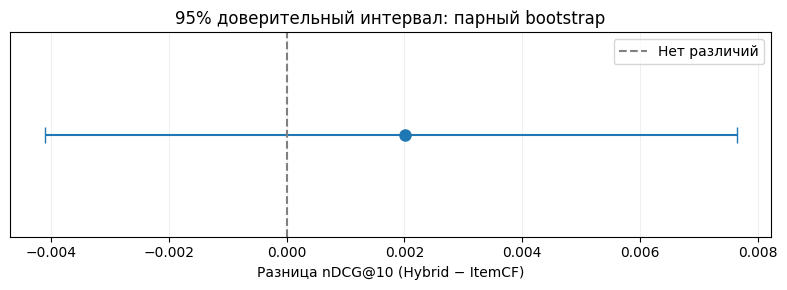

In [54]:
# Визуализация результата парного bootstrap
mean_diff = differences.mean()

plt.figure(figsize=(8, 3))

plt.errorbar(
    mean_diff,
    0,
    xerr=[[mean_diff - ci_lower], [ci_upper - mean_diff]],
    fmt="o",
    capsize=6,
    markersize=8
)

plt.axvline(0, color="gray", linestyle="--", label="Нет различий")

plt.yticks([])
plt.xlabel("Разница nDCG@10 (Hybrid − ItemCF)")
plt.title("95% доверительный интервал: парный bootstrap")
plt.legend()
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


### Вывод по статистической устойчивости

На 200 пользователях Test гибридная модель показала nDCG@10 = 0,2165 против 0,2145 у ItemCF. Средняя разница составила 0,0020.
Парный bootstrap с 5 000 повторными выборками дал 95% доверительный интервал разницы от −0,0041 до 0,0076. Поскольку интервал включает ноль, статистически убедительное преимущество Hybrid над ItemCF не выявлено.

Таким образом, гибридная модель показала сопоставимое с ItemCF качество ранжирования, но её превосходство по nDCG@10 на рассматриваемой выборке не подтверждено.

## Заключение

В ходе проекта разработана гибридная рекомендательная система книг на основе Goodbooks-10k. Реализованы четыре базовых алгоритма, гибридное ранжирование, метод повышения разнообразия MMR и экспериментальный нейросетевой ранжировщик MLP.

**Основные результаты исследования:**

- **ItemCF** оказался наиболее эффективным базовым алгоритмом. На Test он показал лучшие Precision@10 = 0,1950 и Recall@10 = 0,1208.
- **Hybrid** получил наибольший nDCG@10 = 0,2165 против 0,2145 у ItemCF. Однако парный bootstrap на 200 пользователях дал 95% доверительный интервал разницы [−0,0041; 0,0076]. Таким образом, статистически убедительного преимущества Hybrid над ItemCF не обнаружено.
- **MMR** снизил среднее тематическое сходство рекомендованных книг с 0,2619 до 0,1589 (на 39,3%), но nDCG@10 уменьшился до 0,2031. Это демонстрирует компромисс между релевантностью и разнообразием.
- **MLP** показала ROC-AUC = 0,7746 на размеченных взаимодействиях Validation, но не улучшила качество Top-10. Поэтому нейросеть не включена в итоговое ранжирование.
- **Анализ активности пользователей** на расширенной выборке из 300 человек показал наибольший nDCG@10 (0,2501) и Precision@10 (0,2230) в группе высокой активности, что согласуется с предварительными результатами. При этом максимальный Recall@10 (0,1438) получен для пользователей с низкой активностью. Наблюдаемые различия требуют дальнейшей статистической проверки.

Для итоговой системы выбрано гибридное ранжирование с параметрами **K = 5** и весами Content — 0,1, ItemCF — 0,7, Popularity — 0,2, SVD — 0. MMR рассматривается как дополнительный механизм повышения разнообразия, а MLP — как экспериментальный подход, не показавший улучшения.

**Ограничения исследования:** итоговая оценка проведена на подвыборке из 200 пользователей Test с положительными оценками. Небольшие различия между моделями требуют осторожной интерпретации. Обучение MLP только на кандидатах с известными оценками ограничивает применимость её результатов. Для воспроизведения проекта также необходимы подготовленные данные и модели из предыдущего домашнего задания.

**Итог:** гибридная система продемонстрировала качество, сопоставимое с ItemCF, но её статистически убедительное превосходство не установлено. Дополнительные эксперименты позволили оценить влияние параметров, пользовательской активности и разнообразия рекомендаций, а также выявить ограничения нейросетевого подхода.